<a href="https://colab.research.google.com/github/erikh-1126/05-Project-Group/blob/main/05_neural_networks_real_data%20%281%29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Erik H., Henry Y., Derek W."

## 0. Overall Instructions

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

**Descriptive analysis:** We will make a heat map and scatter plot to better visualize our data. We will also include basic statistics like mean, standard deviation, minimum, maximum, and quartiles for each variable.

**Data Preprocessing:** We will remove any null values, create a train-holdout set, and scale the training and potentially the holdout set.

**Model configuration:** This will be a regression function with eight input nodes, two hidden layers with eight nodes each, and one output node. The batch size will be 16. There won't be an activation function for the last output layer, but there is amongst the hidden layers. The cost function will be MSE, and the evaluation metrics will be MSE, RMSE, and R^2. Concrete strength is continuous, so we use MSE loss and one output node without an activation.

**Performance evaluation:** We will use 5-fold cross-validation by randomly dividing the data into five approximately equal groups. In each round, we will train the model on four groups and evaluate it on the remaining group, repeating this until every group has been used for evaluation once.

For each fold, we will fit the scaler only on the training data and use it to transform both the training and validation data to avoid data leakage. We will also initialize and train a fresh model for each fold.

We will calculate MSE, RMSE, and \(R^2\) on each validation fold and report the mean and standard deviation across all five folds. Lower MSE and RMSE indicate smaller prediction errors, while higher \(R^2\) indicates better predictive performance. RMSE is especially useful because it expresses the prediction error in MPa, the same unit as concrete compressive strength.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [ ]:
import os
import sys

# prevent the OpenMP threading conflict found in some macOS installations
if sys.platform == "darwin":
    os.environ["OMP_NUM_THREADS"] = "1"
    os.environ["OPENBLAS_NUM_THREADS"] = "1"
    os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

# small networks run efficiently on one CPU thread.
torch.set_num_threads(1)
print("PyTorch:", torch.__version__)


PyTorch: 2.14.1


Dataset shape: (1030, 9)

Column names:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals)']

Missing values:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)  

,count,mean,std,min,25%,50%,75%,max
Cement (component 1)(kg in a m^3 mixture),1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Fly Ash (component 3)(kg in a m^3 mixture),1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water (component 4)(kg in a m^3 mixture),1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer (component 5)(kg in a m^3 mixture),1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Coarse Aggregate (component 6)(kg in a m^3 mixture),1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Fine Aggregate (component 7)(kg in a m^3 mixture),1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age (day),1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
"Concrete compressive strength(MPa, megapascals)",1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


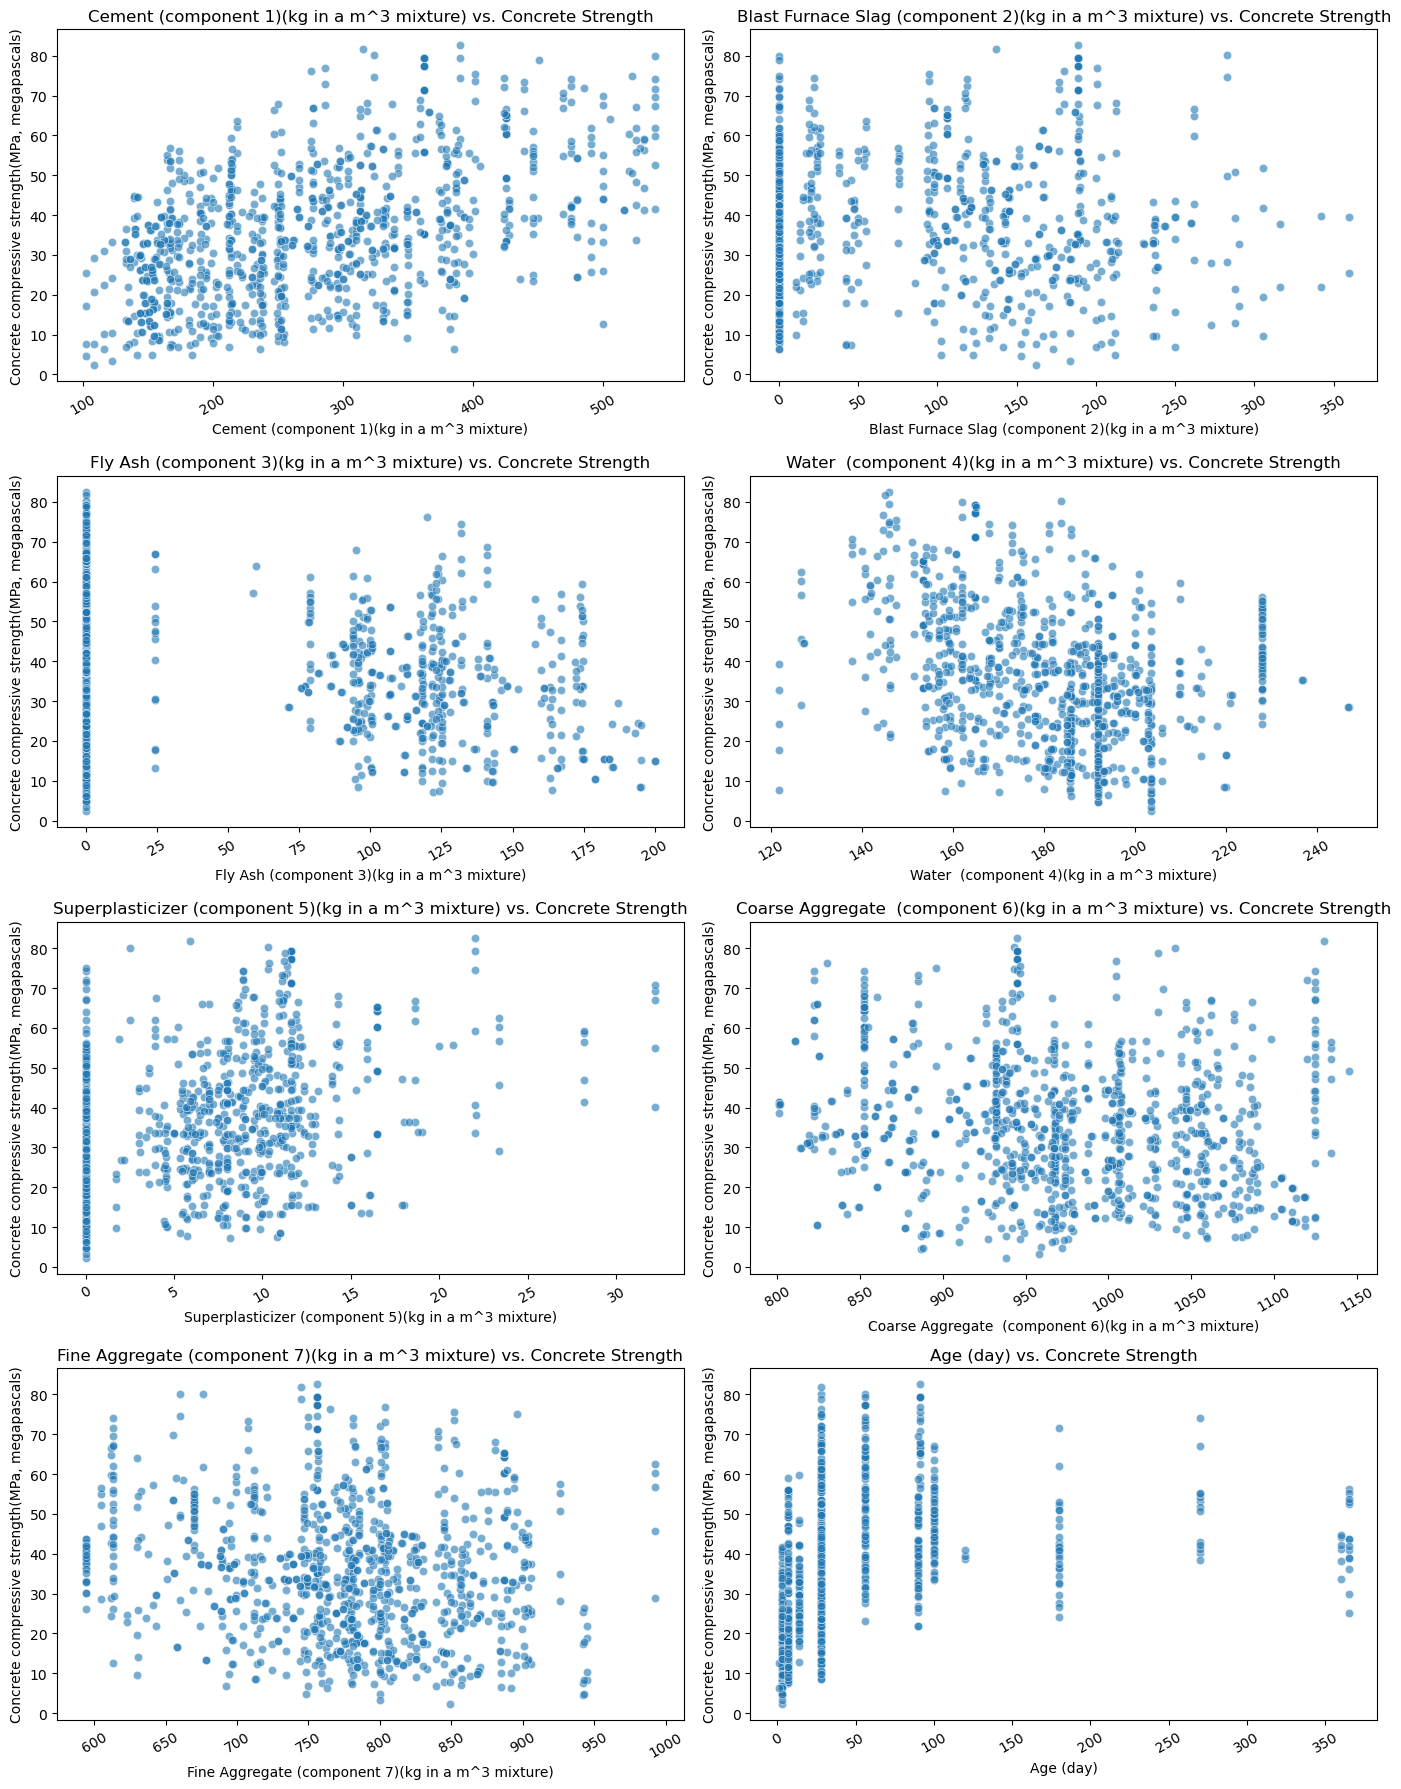

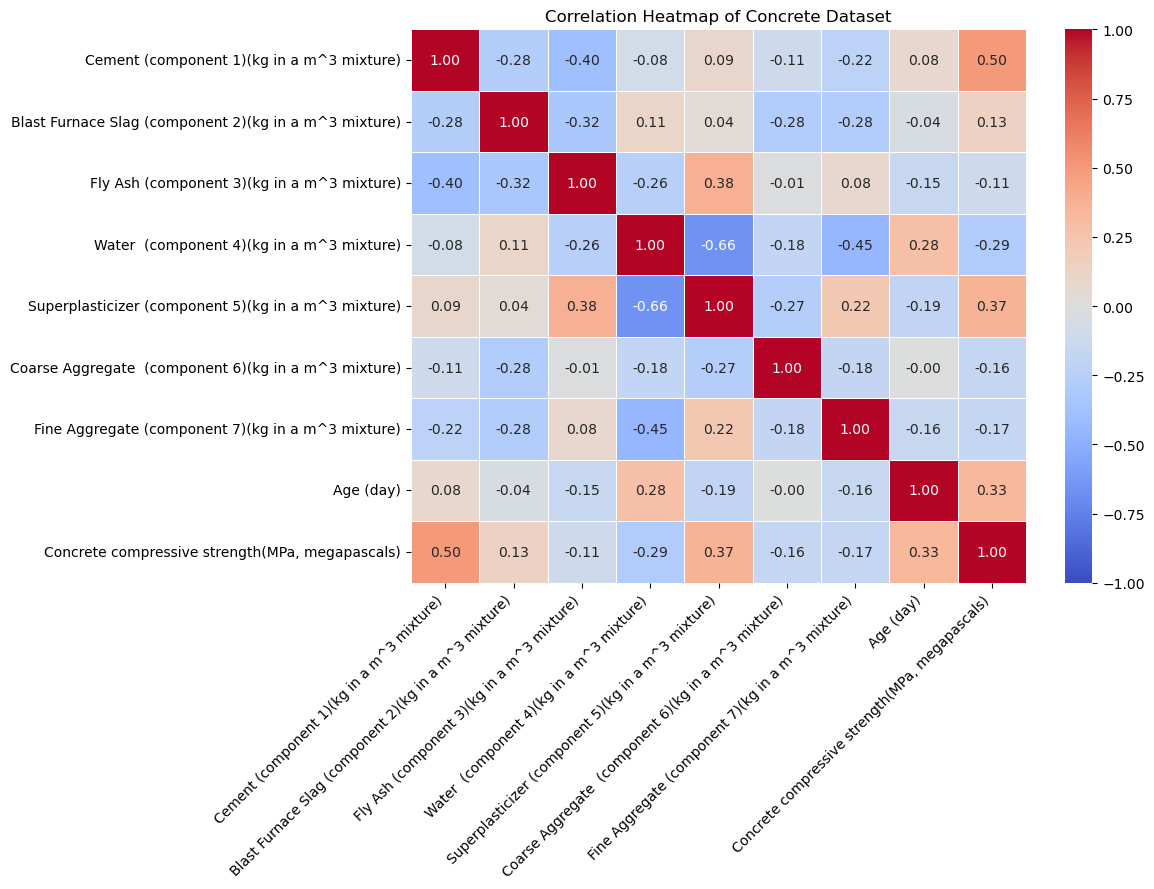

Shape after removing duplicates: (1005, 9)


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# load the dataset
df = pd.read_excel("Concrete_Data.xls")

# clean column names by removing leading/trailing spaces
df.columns = df.columns.str.strip()

# identify the target variable and input features
target = next(
    col for col in df.columns
    if "compressive strength" in col.lower()
)

features = [col for col in df.columns if col != target]

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# check for missing values and duplicate rows
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

# descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe().T.round(2))

# scatter plots
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y=target,
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs. Concrete Strength")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# 3. Correlation heatmap
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Concrete Dataset")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=[target])
y = df[target]

# store raw features here
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training set:", X_train.shape)
print("Holdout set:", X_holdout.shape)


Training set: (804, 8)
Holdout set: (201, 8)


## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [ ]:
class ConcreteNN(nn.Module):

    def __init__(self, input_dim=8, learning_rate=0.001, batch_size=16):
        super().__init__()
        self.learning_rate = learning_rate
        self.batch_size = batch_size

        # define the layers
        l1 = nn.Linear(input_dim, 8)
        a1 = nn.ReLU()
        l2 = nn.Linear(8, 8)
        a2 = nn.ReLU()
        l3 = nn.Linear(8, 1) 
        l = [l1, a1, l2, a2, l3]
        self.module_list = nn.ModuleList(l)

        # each model keeps its own scalers
        self.x_scaler = StandardScaler()
        self.y_scaler = StandardScaler()

    def forward(self, X):
        for f in self.module_list:
            X = f(X)
        return X

    def prepare_data(self, X, y):
        # fit scalers on the training data
        X_scaled = self.x_scaler.fit_transform(X)
        y_scaled = self.y_scaler.fit_transform(np.asarray(y).reshape(-1, 1))
        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        y_t = torch.tensor(y_scaled, dtype=torch.float32)
        return X_t, y_t

    def fit(self, X, y, n_epochs=200):
        X_t, y_t = self.prepare_data(X, y)
        train_dataset = TensorDataset(X_t, y_t)
        train_loader = DataLoader(
            train_dataset, batch_size=self.batch_size, shuffle=True
        )

        cost_function = nn.MSELoss()
        optimizer = optim.Adam(self.parameters(), lr=self.learning_rate)
        self.train_costs = []

        for epoch in range(n_epochs):
            self.train()
            running_cost = 0.0

            for x_batch, y_batch in train_loader:
                optimizer.zero_grad()               
                y_pred = self(x_batch)               
                cost = cost_function(y_pred, y_batch)
                cost.backward()                     
                optimizer.step()                    
                running_cost += cost.item() * len(x_batch)

            self.train_costs.append(running_cost / len(train_dataset))

        return self

    def predict(self, X):
        X_t = torch.tensor(self.x_scaler.transform(X), dtype=torch.float32)
        self.eval()
        with torch.no_grad():
            y_pred = self(X_t).numpy()

        # convert predictions back to MPa
        return self.y_scaler.inverse_transform(y_pred).ravel()

    def evaluate(self, X, y):
        y_pred = self.predict(X)
        mse = mean_squared_error(y, y_pred)
        return {
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R squared": r2_score(y, y_pred)
        }


In [7]:
batch_size = 16
n_epochs = 200
learning_rate = 0.001


kf = KFold(n_splits=5, shuffle=True, random_state=42)

X_cv = X_train.to_numpy()
y_cv = y_train.to_numpy()

cv_splits = list(kf.split(X_cv))
nn_rows = []
nn_histories = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    # model 
    model = ConcreteNN(
        input_dim=X_cv.shape[1],
        learning_rate=learning_rate,
        batch_size=batch_size
    )
    model.fit(X_cv[fit_idx], y_cv[fit_idx], n_epochs=n_epochs)
    nn_histories.append(model.train_costs)

    # evaluate the model on the validation fold
    metrics = model.evaluate(X_cv[val_idx], y_cv[val_idx])
    nn_rows.append({"Fold": fold, **metrics})
    print(f"Fold {fold}: RMSE = {metrics['RMSE']:.3f} MPa, R squared = {metrics['R squared']:.3f}")

nn_cv_results = pd.DataFrame(nn_rows)
display(nn_cv_results.round(3))

# results summary
nn_summary = nn_cv_results[["MSE", "RMSE", "R squared"]].agg(["mean", "std"]).T
print("PyTorch neural network, 5-fold CV (mean and standard deviation across folds):")
display(nn_summary.round(3))


Fold 1: RMSE = 5.415 MPa, R squared = 0.871
Fold 2: RMSE = 5.966 MPa, R squared = 0.852
Fold 3: RMSE = 6.816 MPa, R squared = 0.814
Fold 4: RMSE = 5.784 MPa, R squared = 0.883
Fold 5: RMSE = 6.413 MPa, R squared = 0.848


,Fold,MSE,RMSE,R squared
0,1,29.321,5.415,0.871
1,2,35.592,5.966,0.852
2,3,46.454,6.816,0.814
3,4,33.457,5.784,0.883
4,5,41.124,6.413,0.848


PyTorch neural network, 5-fold CV (mean and standard deviation across folds):


,mean,std
MSE,37.190,6.703
RMSE,6.079,0.547
R squared,0.854,0.026


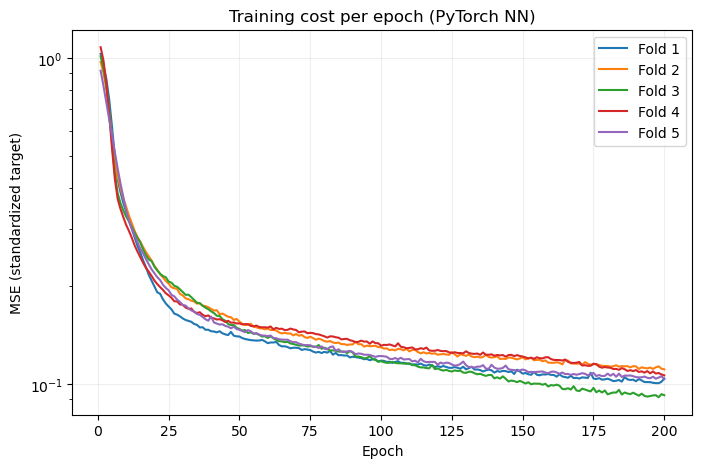

In [8]:
# plot training cost per epoch for each fold
plt.figure(figsize=(8, 5))
for fold, history in enumerate(nn_histories, start=1):
    plt.plot(range(1, n_epochs + 1), history, label=f"Fold {fold}")
plt.title("Training cost per epoch (PyTorch NN)")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized target)")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


PyTorch NN holdout: {'MSE': 37.01, 'RMSE': 6.084, 'R squared': 0.876}


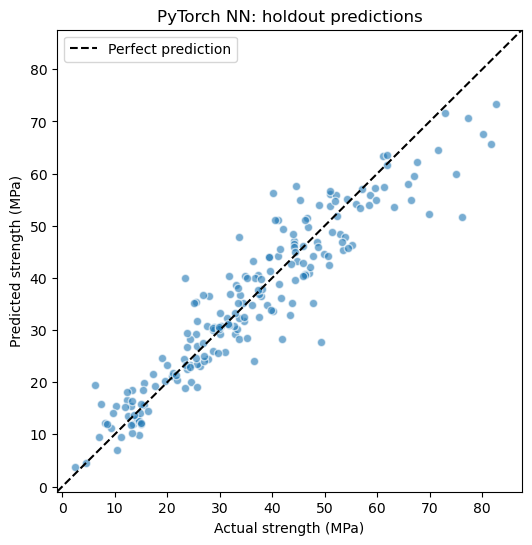

In [ ]:
# train on the full training set
final_nn = ConcreteNN(
    input_dim=X_train.shape[1],
    learning_rate=learning_rate,
    batch_size=batch_size
)
final_nn.fit(X_train, y_train, n_epochs=n_epochs)

nn_holdout = final_nn.evaluate(X_holdout, y_holdout)
print("PyTorch NN holdout:", {k: round(float(v), 3) for k, v in nn_holdout.items()})
y_holdout_pred = final_nn.predict(X_holdout)

plt.figure(figsize=(6, 6))
plt.scatter(y_holdout, y_holdout_pred, alpha=0.6, edgecolors="w")
lims = [min(0, y_holdout.min(), y_holdout_pred.min()) - 1,
        max(y_holdout.max(), y_holdout_pred.max()) + 5]
plt.plot(lims, lims, "k--", label="Perfect prediction")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("PyTorch NN: holdout predictions")
plt.legend()
plt.show()


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [10]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

sk_rows = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    X_fit, X_val = X_cv[fit_idx], X_cv[val_idx]
    y_fit, y_val = y_cv[fit_idx], y_cv[val_idx]

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()
    x_fit_scaled = x_scaler.fit_transform(X_fit)
    X_val_scaled = x_scaler.transform(X_val)
    y_fit_scaled = y_scaler.fit_transform(y_fit.reshape(-1, 1)).ravel()

    model = MLPRegressor(
        hidden_layer_sizes=(8, 8),
        activation="relu",
        solver="adam",
        learning_rate_init=learning_rate,
        batch_size=batch_size,
        max_iter=n_epochs,
        alpha=0.0,
        random_state=42
    )
    model.fit(x_fit_scaled, y_fit_scaled)
    y_pred_scaled = model.predict(X_val_scaled)
    y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    mse = mean_squared_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    sk_rows.append({"Fold": fold, "MSE": mse, "RMSE": np.sqrt(mse), "R squared": r2})
    print(f"Fold {fold}: RMSE = {np.sqrt(mse):.3f} MPa, R squared = {r2:.3f}")

sk_cv_results = pd.DataFrame(sk_rows)
display(sk_cv_results.round(3))

print("sklearn MLP, 5-fold CV (mean and standard deviation): ")
display(sk_cv_results[["MSE", "RMSE", "R squared"]].agg(["mean", "std"]).T.round(3))

Fold 1: RMSE = 5.876 MPa, R squared = 0.849
Fold 2: RMSE = 6.178 MPa, R squared = 0.841
Fold 3: RMSE = 6.913 MPa, R squared = 0.809
Fold 4: RMSE = 5.929 MPa, R squared = 0.877
Fold 5: RMSE = 6.044 MPa, R squared = 0.865


,Fold,MSE,RMSE,R squared
0,1,34.523,5.876,0.849
1,2,38.171,6.178,0.841
2,3,47.788,6.913,0.809
3,4,35.150,5.929,0.877
4,5,36.530,6.044,0.865


sklearn MLP, 5-fold CV (mean and standard deviation): 


,mean,std
MSE,38.432,5.414
RMSE,6.188,0.422
R squared,0.848,0.026


In [11]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()
x_train_scaled = x_scaler.fit_transform(X_train)
X_holdout_scaled = x_scaler.transform(X_holdout)
y_train_scaled = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

final_sk = MLPRegressor(
    hidden_layer_sizes=(8, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=learning_rate,
    batch_size=batch_size,
    max_iter=n_epochs,
    alpha=0.0,
    random_state=42)

final_sk.fit(x_train_scaled, y_train_scaled)
sk_pred = y_scaler.inverse_transform(final_sk.predict(X_holdout_scaled).reshape(-1, 1)).ravel()
sk_mse = mean_squared_error(y_holdout, sk_pred)
sk_r2 = r2_score(y_holdout, sk_pred)
print(f"sklearn MLP holdout: MSE = {sk_mse:.3f}, RMSE = {np.sqrt(sk_mse):.3f}, R squared = {sk_r2:.3f}")

sklearn MLP holdout: MSE = 38.018, RMSE = 6.166, R squared = 0.873


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [12]:
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

svr_rows = []
lr_rows = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
  X_fit, X_val = X_cv[fit_idx], X_cv[val_idx]
  y_fit, y_val = y_cv[fit_idx], y_cv[val_idx]

  x_scaler = StandardScaler()
  y_scaler = StandardScaler()
  X_fit_scaled = x_scaler.fit_transform(X_fit)
  X_val_scaled = x_scaler.transform(X_val)
  y_fit_scaled = y_scaler.fit_transform(y_fit.reshape(-1, 1)).ravel()

  svr = SVR(kernel='rbf')
  svr.fit(X_fit_scaled, y_fit_scaled)
  svr_pred = y_scaler.inverse_transform(svr.predict(X_val_scaled).reshape(-1, 1)).ravel()
  mse = mean_squared_error(y_val, svr_pred)
  r2 = r2_score(y_val, svr_pred)
  svr_rows.append({"Fold": fold, "MSE": mse, "RMSE": np.sqrt(mse), "R squared": r2})

  lr = LinearRegression()
  lr.fit(X_fit_scaled, y_fit_scaled)
  lr_pred = y_scaler.inverse_transform(lr.predict(X_val_scaled).reshape(-1, 1)).ravel()
  mse = mean_squared_error(y_val, lr_pred)
  r2 = r2_score(y_val, lr_pred)
  lr_rows.append({"Fold": fold, "MSE": mse, "RMSE": np.sqrt(mse), "R squared": r2})

  print(f"Fold {fold}: SVR RMSE = {svr_rows[-1]['RMSE']:.3f}, LR RMSE = {lr_rows[-1]['RMSE']:.3f}")

svr_cv_results = pd.DataFrame(svr_rows)
lr_cv_results = pd.DataFrame(lr_rows)

Fold 1: SVR RMSE = 6.574, LR RMSE = 10.101
Fold 2: SVR RMSE = 6.839, LR RMSE = 10.185
Fold 3: SVR RMSE = 6.788, LR RMSE = 10.053
Fold 4: SVR RMSE = 6.957, LR RMSE = 10.182
Fold 5: SVR RMSE = 7.125, LR RMSE = 10.493


In [13]:
comparison = pd.DataFrame({
    "PyTorch NN": nn_cv_results[["MSE", "RMSE", "R squared"]].mean(),
    "sklearn MLP": sk_cv_results[["MSE", "RMSE", "R squared"]].mean(),
    "SVR": svr_cv_results[["MSE", "RMSE", "R squared"]].mean(),
    "Linear Regression": lr_cv_results[["MSE", "RMSE", "R squared"]].mean(),
}).T

comparison["RMSE std"] = [float(r["RMSE"].std()) for r in
                          [nn_cv_results, sk_cv_results, svr_cv_results, lr_cv_results]]

print("5-fold CV comparison, Mean across folds:")
display(comparison.round(3))

5-fold CV comparison, Mean across folds:


,MSE,RMSE,R squared,RMSE std
PyTorch NN,37.190,6.079,0.854,0.547
sklearn MLP,38.432,6.188,0.848,0.422
SVR,47.046,6.857,0.815,0.204
Linear Regression,104.119,10.203,0.589,0.172


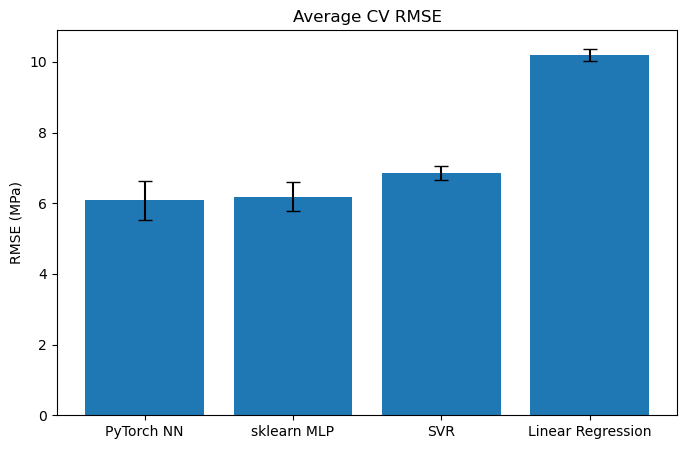

In [14]:
names = ["PyTorch NN", "sklearn MLP", "SVR", "Linear Regression"]
results = [nn_cv_results, sk_cv_results, svr_cv_results, lr_cv_results]

means = [float(r["RMSE"].mean()) for r in results]
stds = [float(r["RMSE"].std()) for r in results]

plt.figure(figsize=(8, 5))
plt.bar(names, means, yerr=stds, capsize=5)
plt.title("Average CV RMSE")
plt.ylabel("RMSE (MPa)")
plt.show()

In [15]:
# fit scalers on the full training set.
final_x_scaler = StandardScaler()
final_y_scaler = StandardScaler()

X_train_scaled = final_x_scaler.fit_transform(X_train)
X_holdout_scaled = final_x_scaler.transform(X_holdout)
y_train_scaled = final_y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

for name, model in [
    ("SVR", SVR(kernel="rbf")),
    ("Linear Regression", LinearRegression())
]:
    model.fit(X_train_scaled, y_train_scaled)

    # convert result back to MPa
    pred_scaled = model.predict(X_holdout_scaled)
    pred = final_y_scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    mse = mean_squared_error(y_holdout, pred)
    r2 = r2_score(y_holdout, pred)

    print(
        f"{name} holdout: MSE = {mse:.3f}, "
        f"RMSE = {np.sqrt(mse):.3f}, R squared = {r2:.3f}"
    )

SVR holdout: MSE = 50.941, RMSE = 7.137, R squared = 0.829
Linear Regression holdout: MSE = 125.265, RMSE = 11.192, R squared = 0.580


The two neural networks performed similarly, with average cross-validation RMSE values of 6.079 MPa for PyTorch and 6.188 MPa for sklearn. SVR performed slightly worse at 6.857 MPa, while linear regression had the highest RMSE at 10.203 MPa, which suggests that nonlinear models capture relationships between concrete ingredients, age, and strength that linear regression misses. These results apply to our chosen settings and folds. They do not establish that one model is always best.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

The biggest challenge that our group faced was not really being able to collaborate simultaneously on certain questions later down the line. For Question 3, which is by far most heavily weighted and important in the lab, it would be beneficial if we were able to collaborate on it together so we could maximize our knowledge on neural networks on PyTorch. Since we had worked with PyTorch and neural networks, we are certain we would be effective at doing so. Now that in the future, the beginning part of labs are going to be on one computer, we can all work on challenging questions at once.